# Submission 1: Dataset, EDA and Related Work
## Waste Image Classification Using Transfer Learning and an Attention-Enhanced Custom CNN: A Comparative Study

**Course:** CSE366 Artificial Intelligence, East West University  
**Instructor:** Dr. Tania Sultana, Assistant Professor, Department of CSE  
**Group:** 08

| Member | Student ID |
|---|---|
| Sadia Afrin | 2024-1-60-149 |
| Md. Nahid Howladar | 2024-1-60-152 |
| Fahmida Kabir | 2024-1-60-154 |
| Tanvir Ahmed | 2024-1-60-156 |

**Contents:** A. Dataset information, B. Exploratory data analysis, C. Related work summary. A stratified split manifest for later submissions is also prepared at the end.

In [7]:
%pip install -q numpy pandas matplotlib seaborn pillow scikit-learn requests

Note: you may need to restart the kernel to use updated packages.


In [8]:
import os, io, zipfile, hashlib, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from PIL import Image
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")

CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
WORK_DIR = Path("trashnet_data")
RESULTS_DIR = Path("results"); FIG_DIR = RESULTS_DIR / "figures"
SPLIT_DIR = Path("splits")
for d in (WORK_DIR, RESULTS_DIR, FIG_DIR, SPLIT_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Setup complete")

Setup complete


## A. Dataset information

### A.1 Download the dataset

The dataset is downloaded from the creators' original repository (https://github.com/garythung/trashnet), the file `data/dataset-resized.zip`. The original repository also points to a Hugging Face copy (https://huggingface.co/datasets/garythung/trashnet). Only the original repository copy is used here, and the files are not redistributed in our repository.

In [9]:
URL = "https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip"

def find_root(base):
    # Find the folder that contains all six class folders (ignores __MACOSX junk).
    for p, dirs, _ in os.walk(base):
        if "__MACOSX" in p:
            continue
        if all(c in dirs for c in CLASSES):
            return Path(p)
    return None

DATA_ROOT = find_root(WORK_DIR)
if DATA_ROOT is None:
    print("Downloading dataset-resized.zip ...")
    r = requests.get(URL, timeout=300)
    r.raise_for_status()
    if len(r.content) < 1_000_000:
        raise RuntimeError("Downloaded file is too small (possibly a Git LFS pointer). "
                           "Download dataset-resized.zip manually from the repository and unzip into ./trashnet_data")
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        z.extractall(WORK_DIR)
    DATA_ROOT = find_root(WORK_DIR)

assert DATA_ROOT is not None, "Class folders not found. Unzip the dataset into ./trashnet_data"
print("Dataset root:", DATA_ROOT)

Dataset root: trashnet_data\dataset-resized


### A.2 Image inventory and integrity check

Every image is opened once to record format, colour mode, size and file size, to detect unreadable files, and to compute an MD5 hash for exact-duplicate detection. The inventory is saved to `results/image_inventory.csv`.

In [10]:
rows = []
for cls in CLASSES:
    for f in sorted((DATA_ROOT / cls).iterdir()):
        if f.name.startswith(".") or f.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp"}:
            continue
        rec = {"path": f"{cls}/{f.name}", "class": cls, "file_bytes": f.stat().st_size,
               "md5": hashlib.md5(f.read_bytes()).hexdigest()}
        try:
            with Image.open(f) as im:
                im.verify()
            with Image.open(f) as im:
                rec.update(format=im.format, mode=im.mode, width=im.size[0], height=im.size[1], readable=True)
        except Exception as e:
            rec.update(format=None, mode=None, width=None, height=None, readable=False)
            print("Unreadable:", f, e)
        rows.append(rec)

inv = pd.DataFrame(rows)
inv.to_csv(RESULTS_DIR / "image_inventory.csv", index=False)
print("Images found:", len(inv), "| unreadable:", int((~inv.readable).sum()))
inv.head()

Images found: 2527 | unreadable: 0


,path,class,file_bytes,md5,format,mode,width,height,readable
0,cardboard/cardboard1.jpg,cardboard,17333,336f2740cc7c60ac7544ad47e34dc602,JPEG,RGB,512,384,True
1,cardboard/cardboard10.jpg,cardboard,21683,b37669c0dcf8eb3939bb35c7be9796fb,JPEG,RGB,512,384,True
2,cardboard/cardboard100.jpg,cardboard,14884,fb79c3308ad68dbac1cf23c244fc0fa5,JPEG,RGB,512,384,True
3,cardboard/cardboard101.jpg,cardboard,14289,733b19b0875874a4804dc2b3bf7a2c08,JPEG,RGB,512,384,True
4,cardboard/cardboard102.jpg,cardboard,18015,eded15aa90832e6144fccb292448ef43,JPEG,RGB,512,384,True


In [11]:
counts = inv["class"].value_counts().reindex(CLASSES)
summary = pd.DataFrame({
    "Field": ["Dataset name", "Creators", "Source link", "Licence", "Year", "Task type",
              "Number of classes", "Total images (counted)", "Image size(s)", "Channels / colour mode",
              "File format(s)", "Collection method", "Capture devices"],
    "Information": [
        "TrashNet",
        "Gary Thung and Mindy Yang",
        "https://github.com/garythung/trashnet (also on Hugging Face: garythung/trashnet)",
        "MIT licence (stated in the repository). The README asks users to cite the repository.",
        "2016 (created for Stanford CS 229, Autumn 2016-2017)",
        "Multi-class, single-label image classification",
        "6 (" + ", ".join(CLASSES) + ")",
        f"{len(inv)} (readable: {int(inv.readable.sum())})",
        ", ".join(f"{w} x {h}" for w, h in inv[["width","height"]].drop_duplicates().itertuples(index=False)),
        ", ".join(f"{m} ({n})" for m, n in inv["mode"].value_counts().items()),
        ", ".join(f"{m} ({n})" for m, n in inv["format"].value_counts().items()),
        "Real objects photographed on white posterboard in sunlight and/or room lighting",
        "Apple iPhone 7 Plus, iPhone 5S and iPhone SE",
    ]
})
pd.set_option("display.max_colwidth", None)
display(summary.style.hide(axis="index"))
print()
display(counts.rename("images").to_frame().assign(percent=(counts / counts.sum() * 100).round(2)))

Field,Information
Dataset name,TrashNet
Creators,Gary Thung and Mindy Yang
Source link,https://github.com/garythung/trashnet (also on Hugging Face: garythung/trashnet)
Licence,MIT licence (stated in the repository). The README asks users to cite the repository.
Year,"2016 (created for Stanford CS 229, Autumn 2016-2017)"
Task type,"Multi-class, single-label image classification"
Number of classes,"6 (cardboard, glass, metal, paper, plastic, trash)"
Total images (counted),2527 (readable: 2527)
Image size(s),512 x 384
Channels / colour mode,RGB (2527)


,images,percent
class,,
cardboard,403,15.95
glass,501,19.83
metal,410,16.22
paper,594,23.51
plastic,482,19.07
trash,137,5.42


**Licence note.** The repository is published under the MIT licence. The licence file belongs to the repository, and the repository does not state a separate licence for the photographs. We therefore use the images only for this course project, cite the original repository, and do not redistribute the data. 

**Year note.** The dataset was created for the Stanford CS 229 course project (Autumn 2016-2017); the creators' report is hosted under the `proj2016` path of the CS 229 website.

### A.3 Why this dataset matters

Waste sorting is a first step in recycling. When materials such as paper, glass, metal and plastic are mixed or contaminated, they are harder and more costly to recycle. Automatic image-based sorting could support smart bins, assist sorting at collection points, and help people decide which bin to use. TrashNet is one of the most widely used public benchmarks for this task, which makes it suitable for comparing training strategies such as transfer learning, training from scratch, and attention modules. Its limitation is its controlled setting (single object, plain white background), so a high score here does not guarantee performance on cluttered real-world photographs.

## B. Exploratory data analysis

### B.1 Class distribution

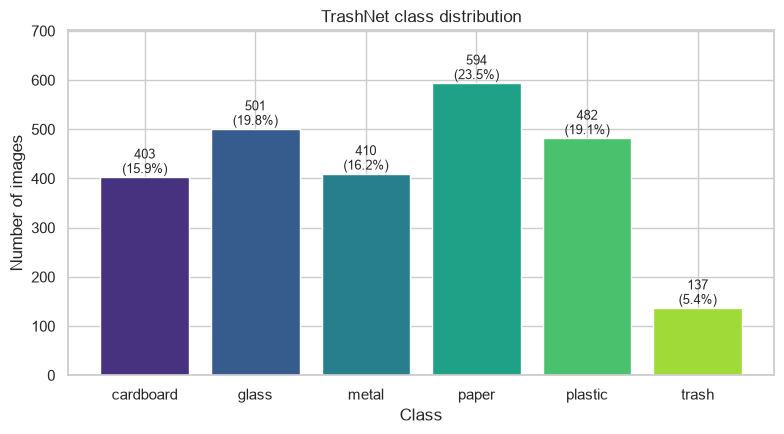

Largest class: paper (594), smallest class: trash (137)
Imbalance ratio (largest / smallest): 4.34
Dataset is imbalanced.


In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = sns.color_palette("viridis", len(CLASSES))
bars = ax.bar(CLASSES, counts.values, color=colors)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 8, f"{v}\n({v/counts.sum()*100:.1f}%)", ha="center", fontsize=9)
ax.set_ylabel("Number of images"); ax.set_xlabel("Class")
ax.set_title("TrashNet class distribution"); ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.savefig(FIG_DIR / "class_distribution.png", dpi=200); plt.show()

ratio = counts.max() / counts.min()
print(f"Largest class: {counts.idxmax()} ({counts.max()}), smallest class: {counts.idxmin()} ({counts.min()})")
print(f"Imbalance ratio (largest / smallest): {ratio:.2f}")
print("Dataset is imbalanced." if ratio > 1.5 else "Dataset is roughly balanced.")

### B.2 Sample images (5 per class)

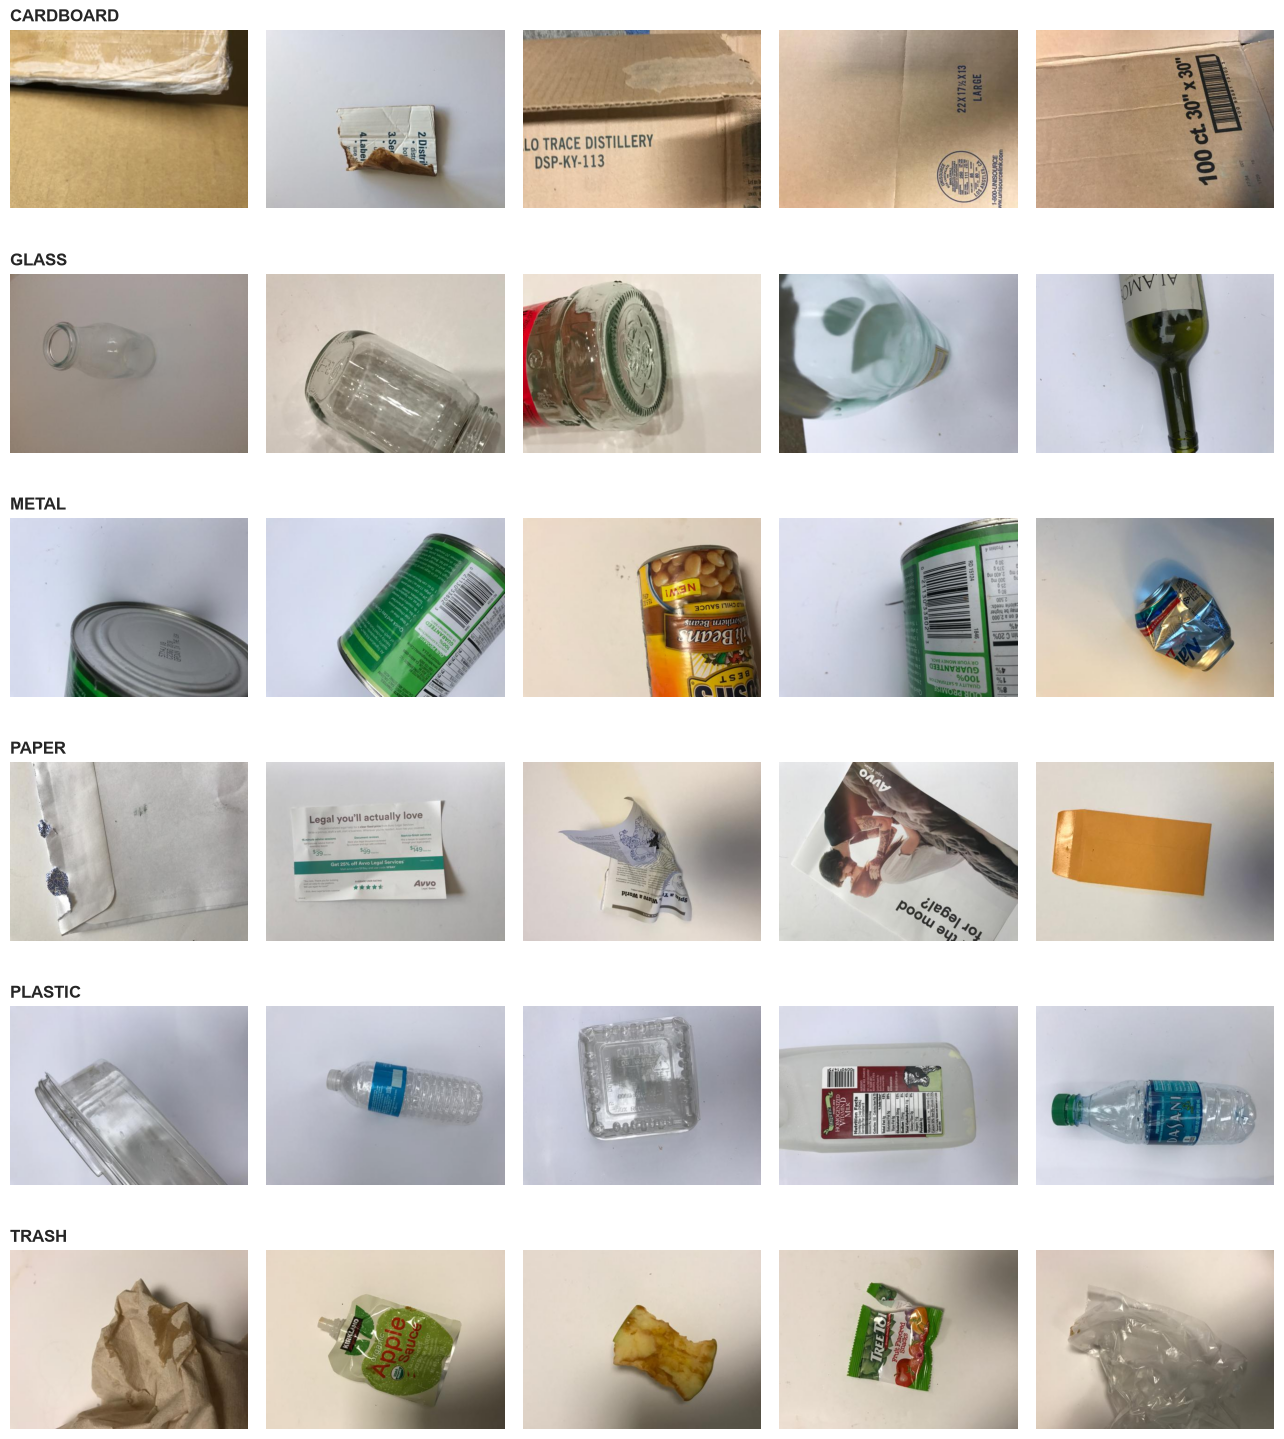

In [13]:
rng = random.Random(SEED)
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(13, 15))
for i, cls in enumerate(CLASSES):
    picks = rng.sample(list(inv.loc[inv["class"] == cls, "path"]), 5)
    for j, p in enumerate(picks):
        axes[i, j].imshow(Image.open(DATA_ROOT / p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls.upper(), loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "sample_grid.png", dpi=150); plt.show()

### B.3 Image size, channels and format

In [14]:
print("Unique (width, height):"); display(inv.groupby(["width", "height"]).size().rename("images").to_frame())
print("Colour modes:"); display(inv["mode"].value_counts().to_frame())
print("File formats:"); display(inv["format"].value_counts().to_frame())
print("File size (KB) by class:")
display((inv.groupby("class")["file_bytes"].describe()[["min", "mean", "max"]] / 1024).round(1))

Unique (width, height):


,,images
width,height,
512,384,2527


Colour modes:


,count
mode,
RGB,2527


File formats:


,count
format,
JPEG,2527


File size (KB) by class:


,min,mean,max
class,,,
cardboard,7.5,18.4,34.1
glass,5.5,13.0,33.0
metal,6.1,17.3,49.2
paper,6.3,21.1,56.5
plastic,5.8,14.1,31.2
trash,6.4,13.8,35.4


### B.4 Duplicates, corrupt files and brightness (possible noise)

Unreadable files: 0
Exact duplicate files (same MD5): 6 in 3 groups


,path,class,md5
421,glass/glass115.jpg,glass,70df08c3ce6d55e25df4edbbe45e5fe3
1305,metal/metal91.jpg,metal,70df08c3ce6d55e25df4edbbe45e5fe3
488,glass/glass176.jpg,glass,a2236bc6f8eae80bf7d6c5f259df8760
1967,plastic/plastic152.jpg,plastic,a2236bc6f8eae80bf7d6c5f259df8760
724,glass/glass389.jpg,glass,e52ec9a8f6089b5780728b148c9f795e
2167,plastic/plastic332.jpg,plastic,e52ec9a8f6089b5780728b148c9f795e


Duplicate groups with conflicting labels: 3


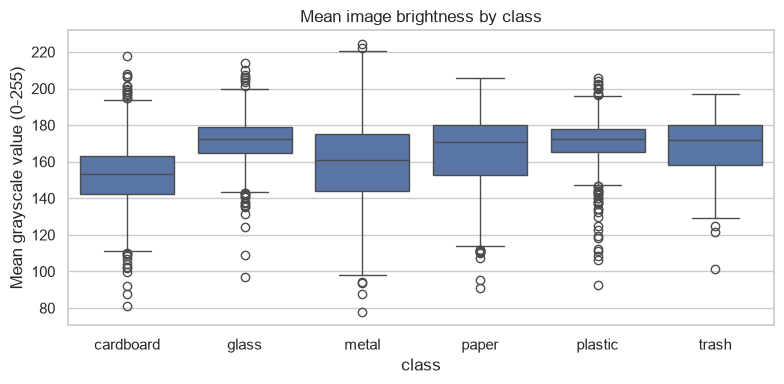

,mean,std,min,max
class,,,,
cardboard,152.8,21.100000,81.099998,217.800003
glass,171.4,14.100000,97.000000,213.800003
metal,158.8,25.100000,77.900002,224.399994
paper,165.8,19.700001,90.900002,206.000000
plastic,170.3,13.900000,92.699997,205.899994
trash,168.0,17.400000,101.599998,196.899994


In [15]:
dup = inv[inv.duplicated("md5", keep=False)].sort_values("md5")
print("Unreadable files:", int((~inv.readable).sum()))
print("Exact duplicate files (same MD5):", len(dup), "in", dup["md5"].nunique(), "groups")
if len(dup):
    display(dup[["path", "class", "md5"]].head(20))
    cross = dup.groupby("md5")["class"].nunique()
    print("Duplicate groups with conflicting labels:", int((cross > 1).sum()))

# mean brightness per image (grayscale, downsampled) to look at lighting variation
def mean_brightness(p):
    with Image.open(DATA_ROOT / p) as im:
        return np.asarray(im.convert("L").resize((64, 48)), dtype=np.float32).mean()
inv["brightness"] = inv["path"].map(mean_brightness)

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=inv, x="class", y="brightness", order=CLASSES, ax=ax)
ax.set_title("Mean image brightness by class"); ax.set_ylabel("Mean grayscale value (0-255)")
plt.tight_layout(); plt.savefig(FIG_DIR / "brightness_by_class.png", dpi=200); plt.show()
display(inv.groupby("class")["brightness"].agg(["mean", "std", "min", "max"]).round(1))

### B.5 Findings

**Class imbalance.** The dataset has 2,527 images. Paper is the largest class (594 images, about 23.5%) and trash is the smallest (137 images, about 5.4%), an imbalance ratio of about 4.3 to 1. Glass (501), plastic (482), metal (410) and cardboard (403) are in between. Accuracy alone could therefore look good even if the model performs poorly on trash, so we will also report per-class precision, recall and F1 and macro-F1.

**Noise and image quality.** All 2,527 images are readable RGB JPEG files of the same size (512 x 384), photographed on a white posterboard, so there is little background clutter and no corrupt file. Lighting still varies: mean brightness is lowest for cardboard (about 153) and metal (about 159, with the widest spread), and higher for glass (about 171) and plastic (about 170), which reflects sunlight versus room-light photographs and material appearance. The duplicate check found **6 exact duplicate files in 3 groups, and in all 3 groups the copies carry different labels** (one glass/metal pair and two glass/plastic pairs). This is label noise inside the benchmark itself. We do not silently change labels: the files are kept with their original labels, documented here, and each duplicate pair is placed in the same split so that identical images never appear in both training and test data. This controlled setup is also a limitation: models may learn the clean-background setting and perform worse on photographs taken in real bins or outdoors.

**Class similarity.** Some classes look alike by material and texture: paper and cardboard (both fibrous and brown or white), and glass, plastic and metal (shiny, transparent or reflective surfaces). The trash class is a mixed group of items and is the smallest, so it is likely to be hardest. We will check this later using confusion matrices.

**Preprocessing and augmentation plan, based on these findings.**
- Resize all images to 224 x 224 RGB, and use each pretrained model's own preprocessing function for the pretrained experiments.
- Use one fixed, stratified train / validation / test split (70/15/15, seed 42) saved as `splits/split_manifest.csv`. Exact duplicate files stay in the same split to prevent leakage; their conflicting labels are documented rather than changed.
- Apply augmentation to the training set only (small rotations, horizontal flips, small zoom and shift, mild brightness changes) to reduce overfitting on a small dataset. We avoid strong colour changes because colour and texture help identify materials.
- Handle imbalance with class weights computed from the training split only, and report macro-F1 and per-class metrics.

### B.6 Split manifest for later submissions

A stratified 70/15/15 split with a fixed seed. Exact duplicates (same MD5) are kept in the same split as their first copy. The same manifest will be reused by every model in Submissions 2-4. Test data will not be used for model selection.

In [16]:
uniq = inv.drop_duplicates("md5", keep="first")[["md5", "path", "class"]].reset_index(drop=True)

train_u, temp_u = train_test_split(uniq, test_size=0.30, stratify=uniq["class"], random_state=SEED)
val_u, test_u = train_test_split(temp_u, test_size=0.50, stratify=temp_u["class"], random_state=SEED)

md5_to_split = {}
for name, part in (("train", train_u), ("val", val_u), ("test", test_u)):
    for h in part["md5"]:
        md5_to_split[h] = name

manifest = inv[["path", "class", "md5"]].copy()
manifest["split"] = manifest["md5"].map(md5_to_split)
manifest = manifest.drop(columns="md5").rename(columns={"class": "label"})
assert manifest["split"].notna().all()
manifest.to_csv(SPLIT_DIR / "split_manifest.csv", index=False)

table = pd.crosstab(manifest["label"], manifest["split"])[["train", "val", "test"]].reindex(CLASSES)
table.loc["total"] = table.sum()
print("Images per class and split (actual integer counts):")
display(table)
print((table.loc["total"] / table.loc["total", :].sum() * 100).round(1).to_dict())

Images per class and split (actual integer counts):


split,train,val,test
label,,,
cardboard,282,61,60
glass,350,75,76
metal,287,62,61
paper,416,89,89
plastic,337,73,72
trash,96,20,21
total,1768,380,379


{'train': 70.0, 'val': 15.0, 'test': 15.0}


## C. Related work summary

Papers (not blog posts) that use TrashNet or closely related waste-image classification. Results are reported by the original authors under their own data splits and protocols, so they are **not directly comparable** with each other or with our later results.

| # | Paper (author, year) | Dataset used | Model(s) | Approach (preprocessing, augmentation, transfer learning, attention) | Result (accuracy / F1 / AUC) | Reference link |
|---|---|---|---|---|---|---|
| 1 | Yu and Grammenos, 2021 | TrashNet; the final model has 5 output classes | GoogLeNet (pretrained, transfer learning) | Base convolutional layers frozen, Adam optimizer (learning rate 2e-5), batch size 16, 81/9/10 train/validation/test split with 10-fold cross-validation. Augmentation: flipping, 180° rotation, 89° shear and 100% zoom | 91.21% test accuracy without augmentation; 95.40% with augmentation | https://arxiv.org/abs/2108.06274 |
| 2 | Kumsetty, Bhat Nekkare, Kamath S. and Anand Kumar M., 2023 | TrashNet and TACO | ResNet and VGG (transfer learning) | Data augmentation and image-processing techniques to improve dataset quality, followed by transfer learning | 93.13% accuracy on TrashNet | https://doi.org/10.1007/978-981-99-0189-0_27 |
| 3 | Nguyen, Do, Phan and Phan, 2025 | TrashNet, Garbage Classification and Household Garbage | Handcrafted-feature ML classifiers; ResNet50, ResNet101, customized ResNet50, EfficientNetV2S; hybrid (ResNet50 features with SVM or Logistic Regression) | Images resized to 400 x 400 with data augmentation; customized ResNet50 head (global average pooling and a dense layer) trained with focal loss | On TrashNet: ResNet50 87.45%, EfficientNetV2S 91.37%, ResNet101 97.59%, customized ResNet50 97.63%; the hybrid model reported 100% accuracy | https://arxiv.org/abs/2510.21833 |

**Note on the results.** The papers use different splits, preprocessing and training protocols, so their scores cannot be ranked against each other or against our results. A reported accuracy of 100% on a small benchmark such as TrashNet should be treated with caution, since the evaluation protocol of the paper determines how reliable it is.

**Relevance to our project.** Paper 1 shows that freezing layers, choosing training settings carefully and using augmentation all affect transfer-learning accuracy, which matches our frozen versus fine-tuned comparison in Submission 2. Paper 2 supports the use of augmentation and transfer learning on TrashNet. Paper 3 compares ResNet50 and EfficientNet variants on TrashNet, which relates to the architectures we plan to test.

### References

1. G. Thung and M. Yang, "TrashNet: Dataset of images of trash," GitHub repository, 2016. [Online]. Available: https://github.com/garythung/trashnet (the repository asks users of the dataset to cite it).

2. G. Thung and M. Yang, "Classification of Trash for Recyclability Status," CS 229 Machine Learning Project Report, Stanford University, Autumn 2016-17. [Online]. Available: https://cs229.stanford.edu/proj2016/report/ThungYang-ClassificationOfTrashForRecyclabilityStatus-report.pdf

3. Y. Yu and R. Grammenos, "Towards artificially intelligent recycling: Improving image processing for waste classification," arXiv:2108.06274 [cs.CV], 2021. [Online]. Available: https://arxiv.org/abs/2108.06274

4. N. V. Kumsetty, A. B. Bhat Nekkare, S. Kamath S. and M. Anand Kumar, "An Approach for Waste Classification Using Data Augmentation and Transfer Learning Models," in Lecture Notes in Electrical Engineering, vol. 1007, Springer, 2023, pp. 357-368. doi: 10.1007/978-981-99-0189-0_27.

5. N.-B.-Q. Nguyen, T.-M. Do, C.-T. Phan and T.-T.-H. Phan, "Towards Accurate and Efficient Waste Image Classification: A Hybrid Deep Learning and Machine Learning Approach," arXiv:2510.21833 [cs.CV], 2025. [Online]. Available: https://arxiv.org/abs/2510.21833